# Corpus atlas: one t-SNE map and candidate clusters (2026-10-21)

Settles the embedding and the candidate clusters for the paper's corpus-atlas figure: SPI–SPI z for the 1,053-recording Zenodo archive (Cliff et al. 2023 used this archive to organise the *statistics*; here the *recordings* are organised). Clusters are fitted in the full retained feature space and only drawn on the map.

Boundaries. Co-location means a shared dependence-organisation signature, not a shared mechanism. Nested windows and M/T variants of one simulation, and price/log-return versions of one market window, are not independent replicates; stability below resamples parent recordings, not rows. t-SNE gap widths, island sizes and inter-cluster distances are partly set by perplexity and exaggeration and are not interpreted. Clusters are illustrative selections, not a taxonomy.

Code: `research/zenodo/atlas/tsne_atlas.py`; settings: `research/zenodo/atlas/configs/analysis/zenodo-tsne-261021.yaml`; cached outputs and the explorer: `results/zenodo_7118947/tsne-261021/`. No pyspi is run.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from threadpoolctl import threadpool_limits

from research.zenodo.atlas import tsne_atlas as ta
%matplotlib inline

ta.notebook_style()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
config = yaml.safe_load(ta.CONFIG.read_text())
OUT = ROOT / config["output"]
FIGURES = OUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
if not (OUT / "manifest.json").exists():
    with threadpool_limits(limits=config["threads"]):
        ta.compute(config, OUT)  # about 6 minutes on 8 cores
R = ta.load(OUT)
corpus = ta.load_corpus(config)
meta, A = corpus["meta"], R["arrays"]
assert (meta.dataset.to_numpy() == A["names"]).all()
print(f"{len(meta)} recordings · {meta.parent.nunique()} parent recordings · origin {meta.origin.value_counts().to_dict()}")

1053 recordings · 688 parent recordings · origin {'real': 566, 'synthetic': 487}


## 1. Feature contract

z must use all M(M−1) ordered off-diagonal MPI entries (`unified_ordered_v3`). The bank declares this contract, but the check below does not rely on the label: it recomputes every row from the 1,053 stored seeded MPI files with the library builder and compares bit for bit (float32). The upper-triangle symmetrised alternative is scored on every 50th row to show the comparison can tell the contracts apart.

In [2]:
check = ta.verify_contract(corpus, ROOT / config["mpi_runs"])
pd.Series(check)

rows                                        1053
max_abs_difference                           0.0
finite_pattern_mismatches                      0
upper_symmetrised_max_difference_min    0.462721
upper_symmetrised_rows_checked                22
asymmetric_directed_mpis_last_row       0.936937
entries_per_mpi                           M(M-1)
dtype: object

In [3]:
assert check["max_abs_difference"] < 1e-6 and check["finite_pattern_mismatches"] == 0
assert check["upper_symmetrised_max_difference_min"] > 0.1
print("Bank = unified_ordered_v3 recomputed from MPIs; the symmetrised contract differs by at least",
      round(check["upper_symmetrised_max_difference_min"], 2), "on every checked row.")

Bank = unified_ordered_v3 recomputed from MPIs; the symmetrised contract differs by at least 0.46 on every checked row.


## 2. Preprocessing variants

*Primary*: SPI-pair features finite for ≥95% of recordings; per-feature median imputation of the remaining entries; drop features with SD < 1e−8; centre (no scaling). *complete*: only features finite for every recording (no imputation). *valid90*: ≥90% finite. *standardised*: primary, then unit variance per feature. *historical*: the old `CorrelationFrame` defaults (duplicate features dropped, ≥80% finite, zero fill, no centring). Every variant keeps all 1,053 rows. `nn15_vs_primary` is the mean overlap of each recording's 15 nearest neighbours with those in the primary geometry.

In [4]:
grid = R["grid"].set_index("key")
variants = R["variants"].copy()
variants["map_recall15_vs_primary"] = [grid.loc[f"{v}-p30-x1-pca", "recall15_full"] for v in variants.index]
variants["map_regions"] = [grid.loc[f"{v}-p30-x1-pca", "map_regions"] for v in variants.index]
variants["map_regions_sil_full"] = [grid.loc[f"{v}-p30-x1-pca", "regions_sil_full"] for v in variants.index]
x_primary, _ = ta.preprocess(corpus["raw"], "primary")
sd = x_primary.std(axis=0)
missing = ~np.isfinite(corpus["raw"][:, A["keep_indices"]])
print(f"Primary: {x_primary.shape[1]:,} features; SD range {sd.min():.4f}–{sd.max():.2f}, {int((sd < .01).sum())} features with SD < 0.01; "
      f"{missing.mean():.1%} of entries imputed, {int((missing.mean(axis=1) > .2).sum())} rows with > 20% imputed: "
      + ", ".join(sorted(set(meta.source[missing.mean(axis=1) > .2]))))
variants.round(3)

Primary: 21,788 features; SD range 0.0009–0.63, 35 features with SD < 0.01; 1.4% of entries imputed, 30 rows with > 20% imputed: Brownian motion, Oscillator hysteresis, Oscillator sync, PEMS-SF, Wave 1D, Wave 2D


,features,imputed_fraction,rows_over_20pct_imputed,nn15_vs_primary,variance_pc2,map_recall15_vs_primary,map_regions,map_regions_sil_full
primary,21788.0,0.014,30.0,1.000,0.292,0.495,25.0,0.098
complete,9313.0,0.000,0.0,0.755,0.383,0.454,25.0,0.094
valid90,22936.0,0.017,30.0,0.967,0.286,0.494,26.0,0.084
standardised,21788.0,0.014,30.0,0.823,0.229,0.471,3.0,0.135
historical,28066.0,0.038,NaN,0.869,0.285,0.477,28.0,0.096


## 3. Candidate embeddings

All t-SNE maps: scikit-learn Barnes–Hut, 1,500 iterations, early exaggeration 12 for 250 iterations, automatic learning rate, five seeds per setting. Exaggeration ρ is a constant multiplier on the attractive term after the early phase (Böhm, Berens & Kobak 2022); ρ = 1 is standard t-SNE. Input "primary" is the exact full-rank PCA of all 21,788 retained features, so its distances equal the full feature-space distances; "pcaK" truncates to K components. PC1–PC2 is the linear reference.

Metrics, all against the full primary feature space:
- `recallK_full`: fraction of each recording's K nearest full-space neighbours that are also among its K nearest map neighbours (K = 5, 15, 50); `recall15_complete` uses the imputation-free complete-feature geometry instead.
- `map_regions`, `regions_sil_2d`, `regions_sil_full`: HDBSCAN (min cluster size 10) on the 2-D map gives what a reader would call clusters; their silhouette is measured in 2-D and again in the full space. The gap between the two is separation the map adds.
- `partition_sil_2d`: 2-D silhouette of the fixed feature-space Ward-40 partition (its full-space silhouette is 0.10 in every map).
- `seed_*`: agreement between the five seeds (15-NN overlap, Procrustes disparity, ARI of map regions). `subsample_nn15_vs_full_map`: maps refitted on ten parent-grouped 80% subsets, 15-NN overlap with the full map on the retained points.

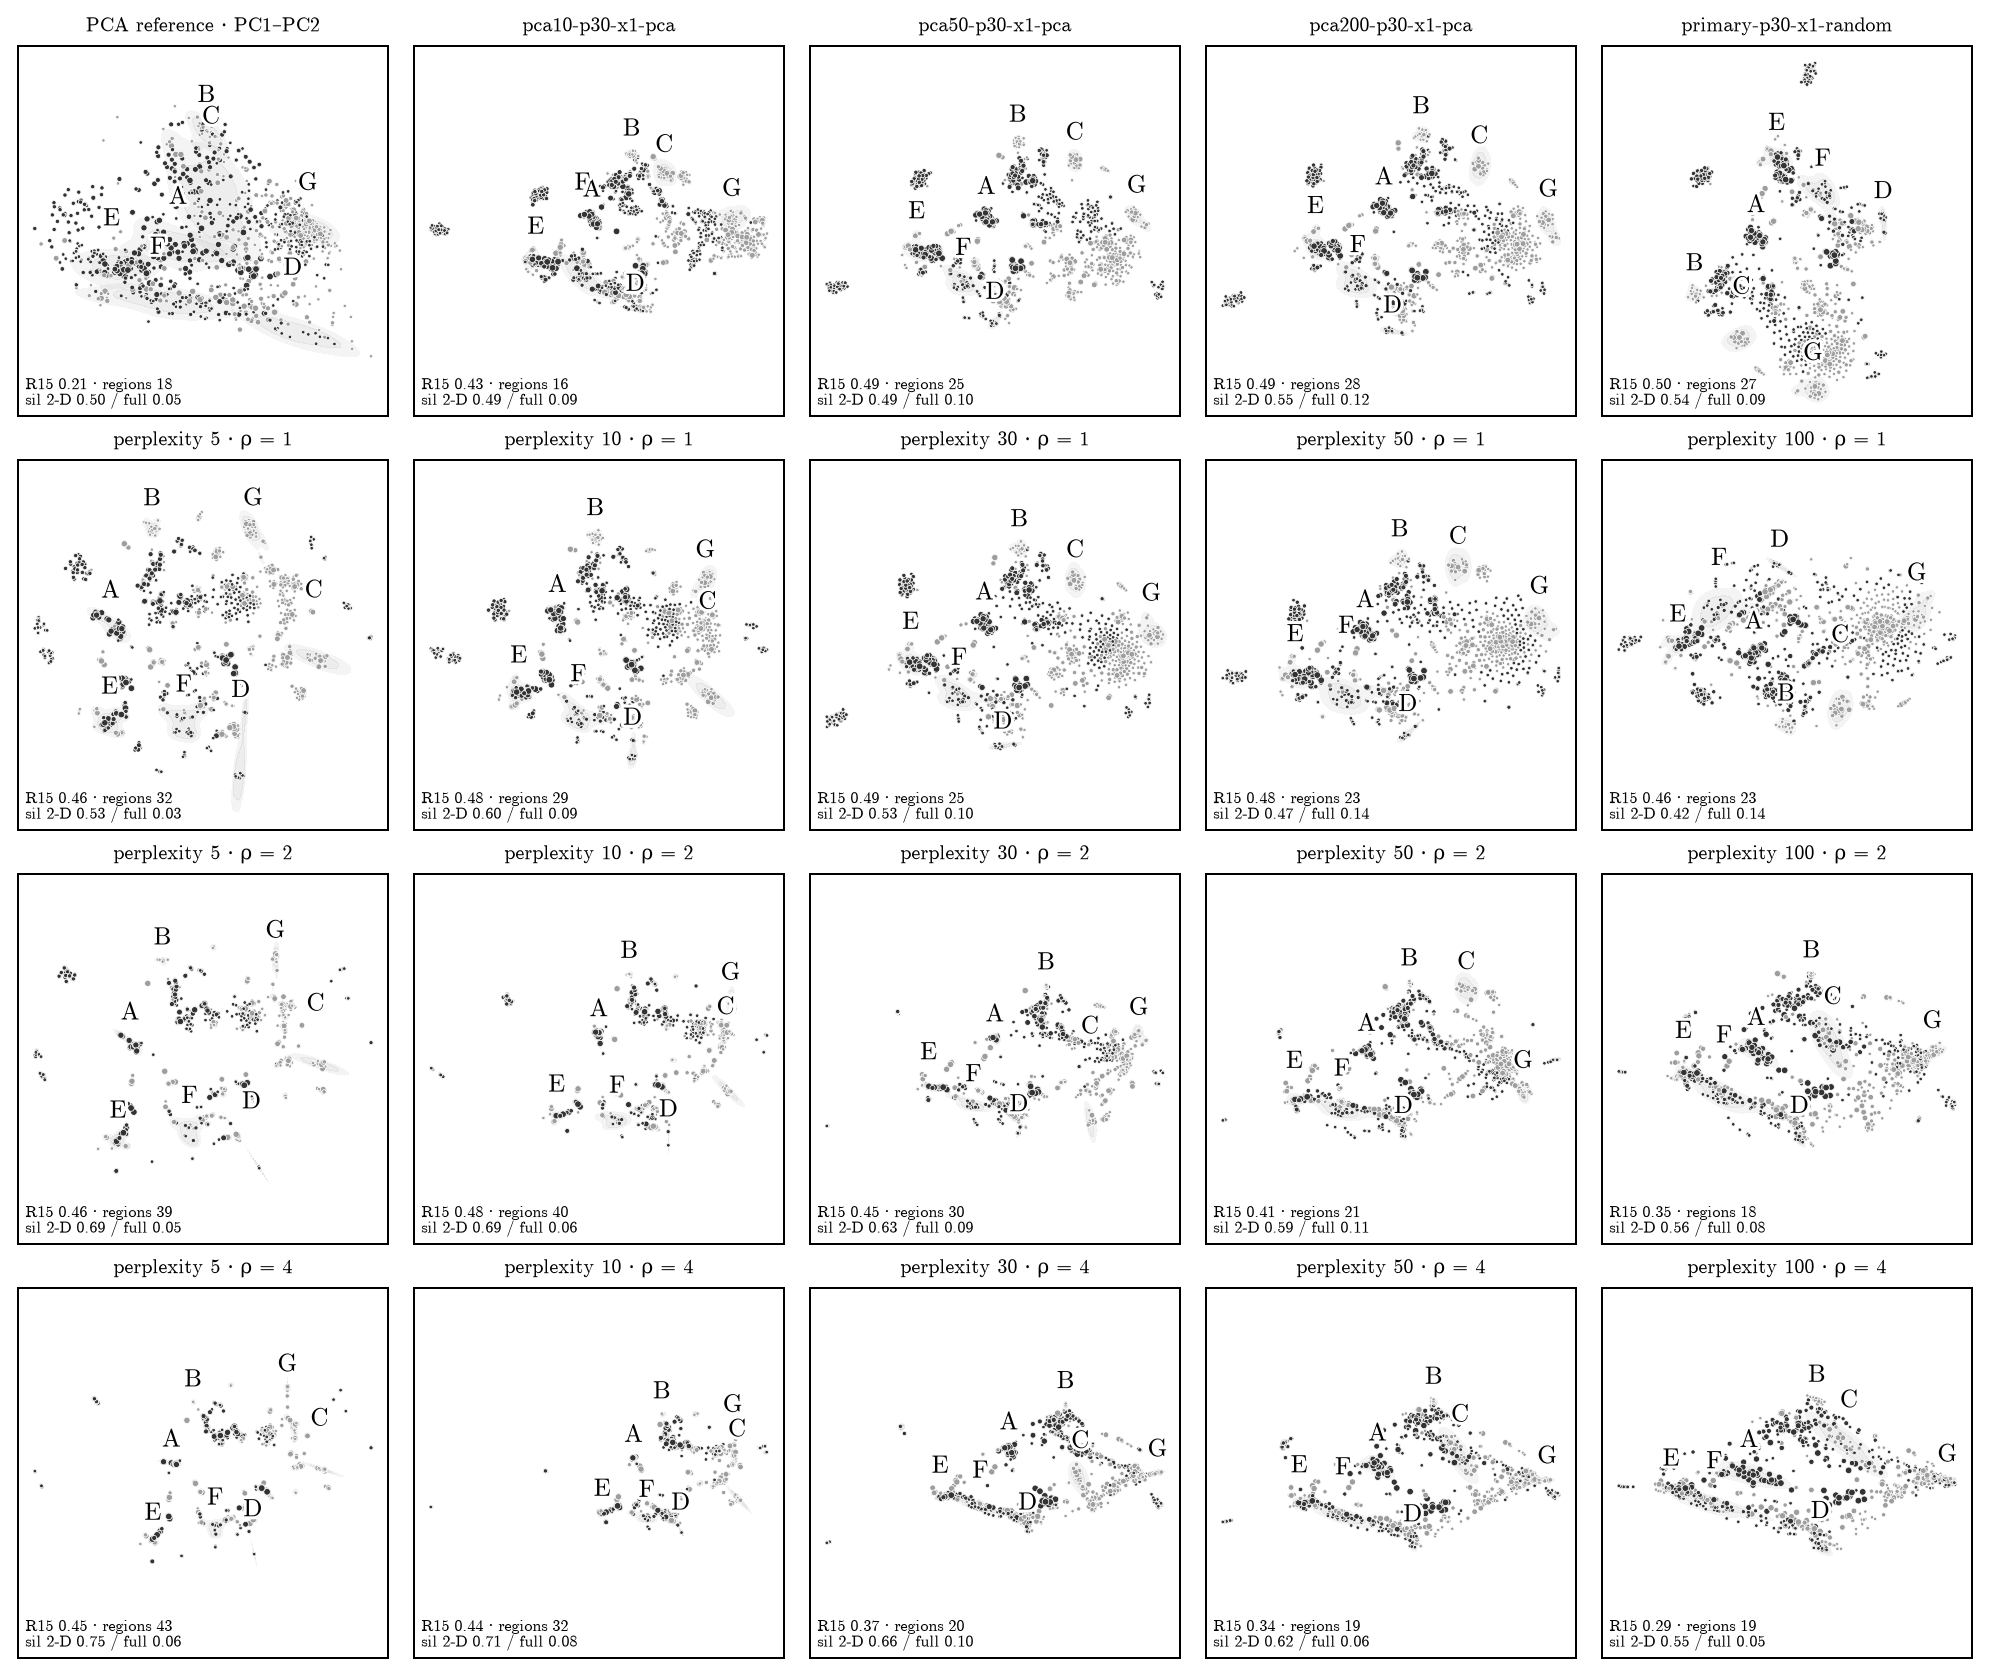

In [5]:
labels = A["partition__ward40"]
CANDIDATES = {  # Ward-40 cluster id -> (letter, short title); selection rationale in section 7
    35: ("A", "NATOPS gestures"),
    21: ("B", "NetSim fMRI simulations"),
    20: ("C", "Coupled map lattices + synthetic weather"),
    4: ("D", "Cricket accelerometry + ForEx prices"),
    34: ("E", "PEMS-SF traffic + LEGION oscillators + geometric Brownian motion"),
    39: ("F", "Trending series: articulation, cricket, Brownian motion, stock prices"),
    6: ("G", "Heavy-tailed noise + TestWEATH with 999 missing-value codes"),
}
LETTERS = {c: v[0] for c, v in CANDIDATES.items()}

def first(key):
    xy = A[f"map__{key}"]
    return xy[0] if xy.ndim == 3 else xy

def panel(ax, key, title=None):
    ta.plot_atlas(ax, first(key), meta, labels, LETTERS, size=.45)
    g = grid.loc[key]
    ax.set_title(title or key, fontsize=8)
    ax.text(.02, .02, f"R15 {g.recall15_full:.2f} · regions {int(g.map_regions)}\nsil 2-D {g.regions_sil_2d:.2f} / full {g.regions_sil_full:.2f}",
            transform=ax.transAxes, fontsize=6.5, va="bottom")

fig, axes = plt.subplots(4, 5, figsize=(11, 9.2))
panel(axes[0, 0], "pc1-pc2", "PCA reference · PC1–PC2")
for ax, key in zip(axes[0, 1:], ["pca10-p30-x1-pca", "pca50-p30-x1-pca", "pca200-p30-x1-pca", "primary-p30-x1-random"]):
    panel(ax, key)
for row, rho in zip(axes[1:], [1, 2, 4]):
    for ax, p in zip(row, config["perplexities"]):
        panel(ax, f"primary-p{p}-x{rho}-pca", f"perplexity {p} · ρ = {rho}")
fig.savefig(FIGURES / "embedding-grid.png", dpi=150)
plt.show()

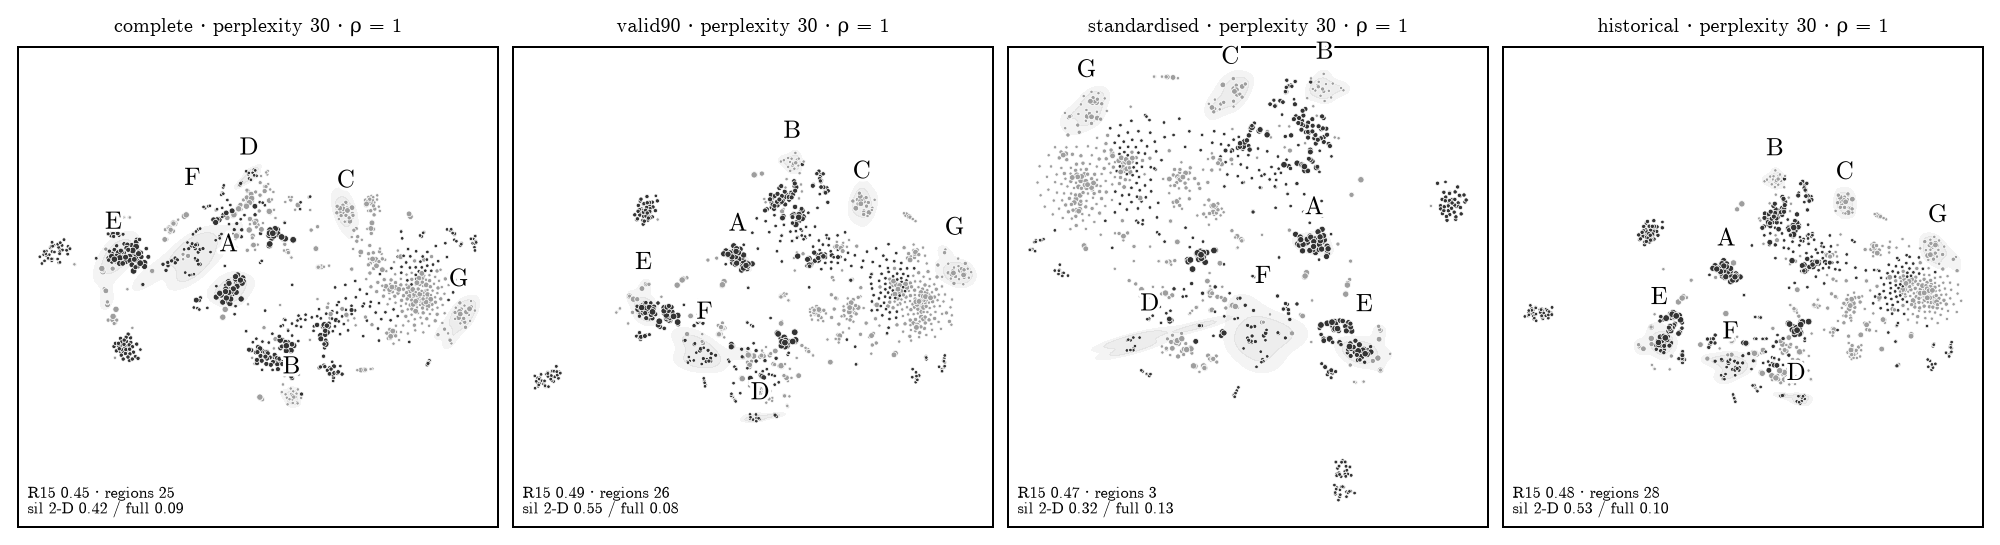

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(11, 3))
for ax, v in zip(axes, config["variants"]):
    panel(ax, f"{v}-p30-x1-pca", f"{v} · perplexity 30 · ρ = 1")
plt.show()

In [7]:
cols = ["recall5_full", "recall15_full", "recall50_full", "recall15_complete", "map_regions", "regions_sil_2d", "regions_sil_full",
        "partition_sil_2d", "partition_nn15_same_2d", "seed_nn15_overlap", "seed_procrustes_disparity", "seed_regions_ari",
        "subsample_nn15_vs_full_map"]
grid[cols].round(3)

,recall5_full,recall15_full,recall50_full,recall15_complete,map_regions,regions_sil_2d,regions_sil_full,partition_sil_2d,partition_nn15_same_2d,seed_nn15_overlap,seed_procrustes_disparity,seed_regions_ari,subsample_nn15_vs_full_map
key,,,,,,,,,,,,,
pc1-pc2,0.113,0.205,0.343,0.211,18.0,0.503,0.050,-0.165,0.325,NaN,NaN,NaN,NaN
primary-p5-x1-pca,0.500,0.457,0.422,0.434,32.0,0.529,0.034,0.261,0.696,0.939,0.007,0.847,NaN
primary-p5-x2-pca,0.481,0.458,0.424,0.436,39.0,0.689,0.051,0.310,0.702,0.990,0.003,0.962,NaN
primary-p5-x4-pca,0.424,0.451,0.426,0.433,43.0,0.749,0.060,0.343,0.712,0.989,0.001,0.916,NaN
primary-p10-x1-pca,0.512,0.482,0.436,0.459,29.0,0.597,0.087,0.270,0.712,0.934,0.003,0.894,NaN
primary-p10-x2-pca,0.453,0.477,0.442,0.456,40.0,0.687,0.062,0.347,0.721,0.985,0.001,0.901,NaN
primary-p10-x4-pca,0.376,0.441,0.439,0.421,32.0,0.712,0.082,0.331,0.718,0.995,0.001,0.965,NaN
primary-p30-x1-pca,0.487,0.495,0.461,0.478,25.0,0.527,0.098,0.246,0.709,0.948,0.001,0.870,0.720
primary-p30-x2-pca,0.366,0.447,0.466,0.437,30.0,0.630,0.092,0.314,0.715,0.998,0.000,0.979,0.782


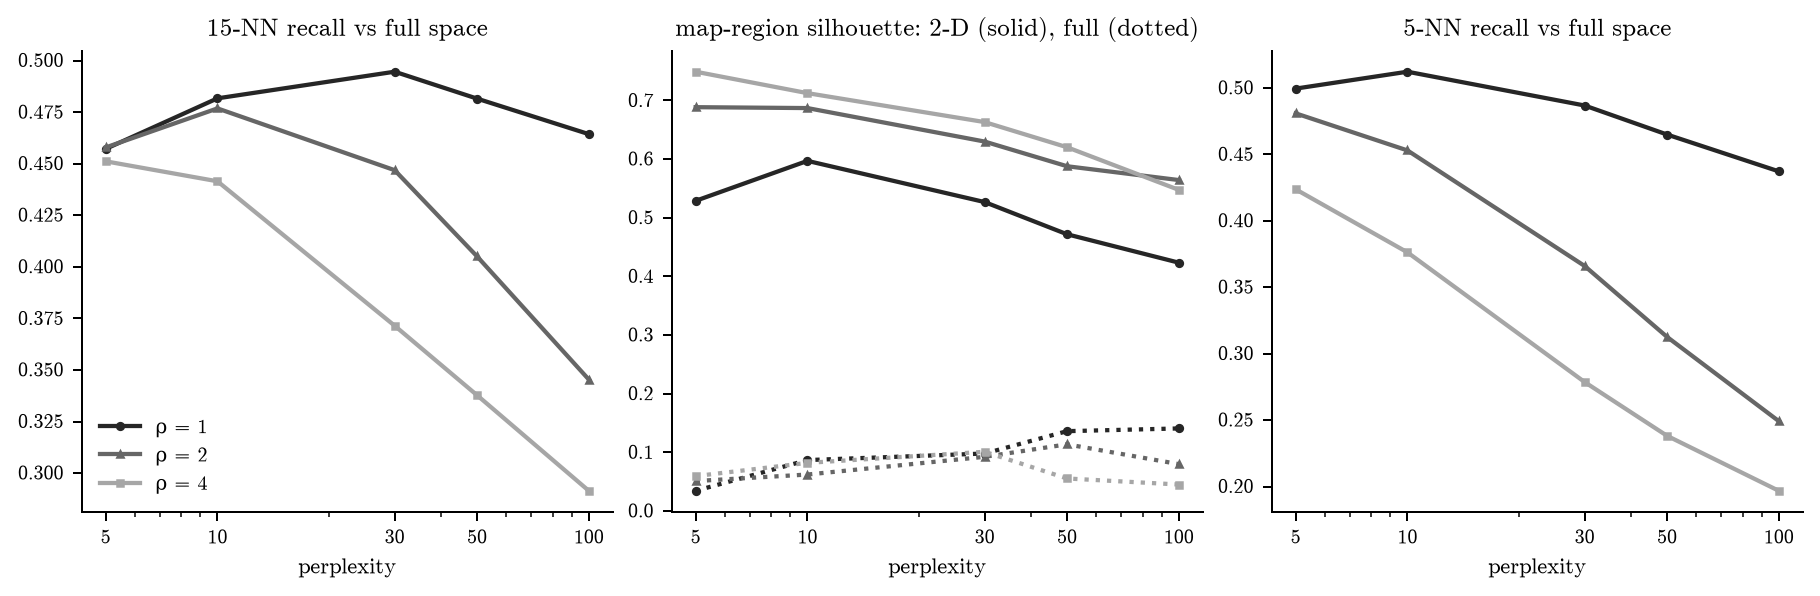

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
sweep = grid[grid.group == "perplexity × exaggeration"]
for rho, marker in zip([1, 2, 4], "o^s"):
    s = sweep[sweep.exaggeration == rho].sort_values("perplexity")
    axes[0].plot(s.perplexity, s.recall15_full, marker=marker, color=str(.15 + .25 * np.log2(rho)), label=f"ρ = {rho}")
    axes[1].plot(s.perplexity, s.regions_sil_2d, marker=marker, color=str(.15 + .25 * np.log2(rho)))
    axes[1].plot(s.perplexity, s.regions_sil_full, marker=marker, ls=":", color=str(.15 + .25 * np.log2(rho)))
    axes[2].plot(s.perplexity, s.recall5_full, marker=marker, color=str(.15 + .25 * np.log2(rho)))
for ax, label in zip(axes, ["15-NN recall vs full space", "map-region silhouette: 2-D (solid), full (dotted)", "5-NN recall vs full space"]):
    ax.set(xscale="log", xlabel="perplexity", title=label)
    ax.set_xticks(config["perplexities"], config["perplexities"])
axes[0].legend()
fig.savefig(FIGURES / "tradeoff.png", dpi=150)
plt.show()

## 4. Preprocessing and method: what should be used, what looks cleanest

"Cleanest" is read quantitatively as visual separation (2-D silhouette of map regions or of the feature-space partition, number of islands) and checked against the full feature space (silhouette of the same groups there, neighbour recall). Numbers cite the tables above.

| Choice | What it is | Should be used, and why | Cleanest | Coincide? |
|---|---|---|---|---|
| Finite-fraction filter | Keep an SPI-pair feature only if it is finite for ≥ q of recordings. | q = 0.95, declared before this study. The threshold trades statistic coverage against imputation load and has no unique principled value. 90% gives the same geometry (15-NN overlap 0.97); 100% keeps 9,313 features and is the imputation-free check (overlap 0.76). | No variant is cleaner: map metrics at 90/95% are within seed noise; complete-case maps recall the full space less well. | Yes |
| Imputation | Per-feature median for the 1.4% missing entries; 30 rows carry > 20% (16 PEMS-SF days, 9 wave and 2 oscillator simulations, 3 Brownian motion). | Median, with the complete-feature refit as a check on every cluster. Zero fill (historical) asserts "no agreement", which is a substantive value for a correlation. Shared imputed values can make high-missingness rows look alike, so clusters dominated by them need the complete-feature check. | Zero fill looks about the same (R15 0.48). | Yes |
| Near-constant removal | Drop features with SD < 1e−8 (exact constants). | Keep. It is a no-op for centred Euclidean distances. It matters only before standardising, where 1e−8 does not protect against the 35 features with SD < 0.01. | No effect. | Yes |
| Centring vs standardising | Centring is needed for PCA and leaves distances unchanged. Standardising gives every SPI pair unit variance. | Centre only. All features are correlations on one [−1, 1] scale; correlation-matrix PCA is for incommensurate units (Jolliffe & Cadima 2016). Standardising up-weights low-variance pairs, mostly near-duplicate estimators whose variation is estimation noise, and changes the geometry (15-NN overlap 0.82). | Not cleaner: it merges the map into 3 coarse HDBSCAN regions. | Yes |
| PCA dimension before t-SNE | Truncate the input to K principal components. | Full rank. At N = 1,053 the exact input costs about 2 s per map; 50 PCs is a speed and denoising convention (van der Maaten & Hinton 2008; Kobak & Berens 2019) that discards 27.5% of variance. PCA200 matches full rank; PCA10 loses neighbours (R15 0.43). | PCA50 draws the Ward-40 clusters more compactly (2-D silhouette 0.35 vs 0.25; same-cluster 15-NN 0.80 vs 0.71) at the same recall (0.492 vs 0.495). The reason: Ward-40 is twice as separated in PCA50 space (silhouette 0.20) as in the full space (0.10). The gain comes from truncation, not from the full geometry. | Mildly diverge |
| Perplexity | Effective neighbourhood size of the input affinities. | 30. It maximises 15-NN recall (0.495; 0.48 at 10 and 50) and is conventional (5–50; N/100 ≈ 10 is similar here). Larger values keep more mid-range structure (50-NN recall peaks at 50–100) but lose local recall and seed reproducibility (seed 15-NN overlap 0.74 at 50 and 100). | Perplexity 5–10 fragments the map into 29–43 islands (most with ρ ≥ 2), with 2-D silhouette up to 0.75. Their full-space silhouette is 0.03–0.09, no better than the baseline's 0.10 (cf. Wattenberg et al. 2016). | Diverge |
| Exaggeration ρ | Constant multiplier on attraction after the early phase. | ρ = 1 (standard t-SNE). ρ > 1 moves along the attraction–repulsion spectrum toward UMAP-like (ρ ≈ 4) and Laplacian-eigenmap layouts (Böhm et al. 2022), compacting clusters and widening gaps. At perplexity 30, R15 falls 0.495 → 0.447 → 0.371 and R5 0.487 → 0.366 → 0.279 for ρ = 1, 2, 4, while map-region silhouette rises 0.53 → 0.63 → 0.66 in 2-D and stays 0.10 → 0.09 → 0.10 in the full space. | ρ = 2–4. ρ = 2 also improves seed and subsample stability (0.72 → 0.78), but by tightening the map, not by recovering full-space neighbours. | Diverge |
| Initialisation | PCA (scaled PC1–PC2) versus random. | PCA (Kobak & Linderman 2021): it fixes the global arrangement to the leading variance directions and is reproducible. Recall is identical (0.495); seed 15-NN overlap 0.95 vs 0.90. | Indistinguishable. | Yes |
| Seed | With PCA initialisation, the seed enters only through the randomised SVD of the initialisation. | Fix (1729) and report: at perplexity 30, ρ = 1, seed 15-NN overlap is 0.95 and Procrustes disparity 0.001. The more relevant stability is data-level: refitting on parent-grouped 80% subsets keeps 72% of 15-NN. | — | Yes |

**Verdict.** The principled and the cleanest-looking settings diverge on perplexity, exaggeration and, mildly, PCA truncation. The visual gains from low perplexity and ρ ≥ 2 are separation that the full feature space does not have: the full-space silhouette of their islands does not improve, and local neighbour recall falls by 10–40%. **Recommendation:** primary preprocessing, exact full-rank input, PCA initialisation, perplexity 30, ρ = 1, seed 1729. The PCA50 map is a defensible, near-identical alternative if crisper groups matter more than fidelity to the full geometry; disclose the truncation if it is used. Do not use ρ ≥ 2 or perplexity ≤ 10 for the figure.

What the chosen map still trades away: about half of each recording's 15 nearest full-space neighbours (R15 0.495) are its map neighbours. Global distances and island sizes are not interpretable. Global feature-space cluster structure is weak (Ward-40 silhouette 0.10), so the map is mostly a continuum with a minority of compact groups.

## 5. Chosen map

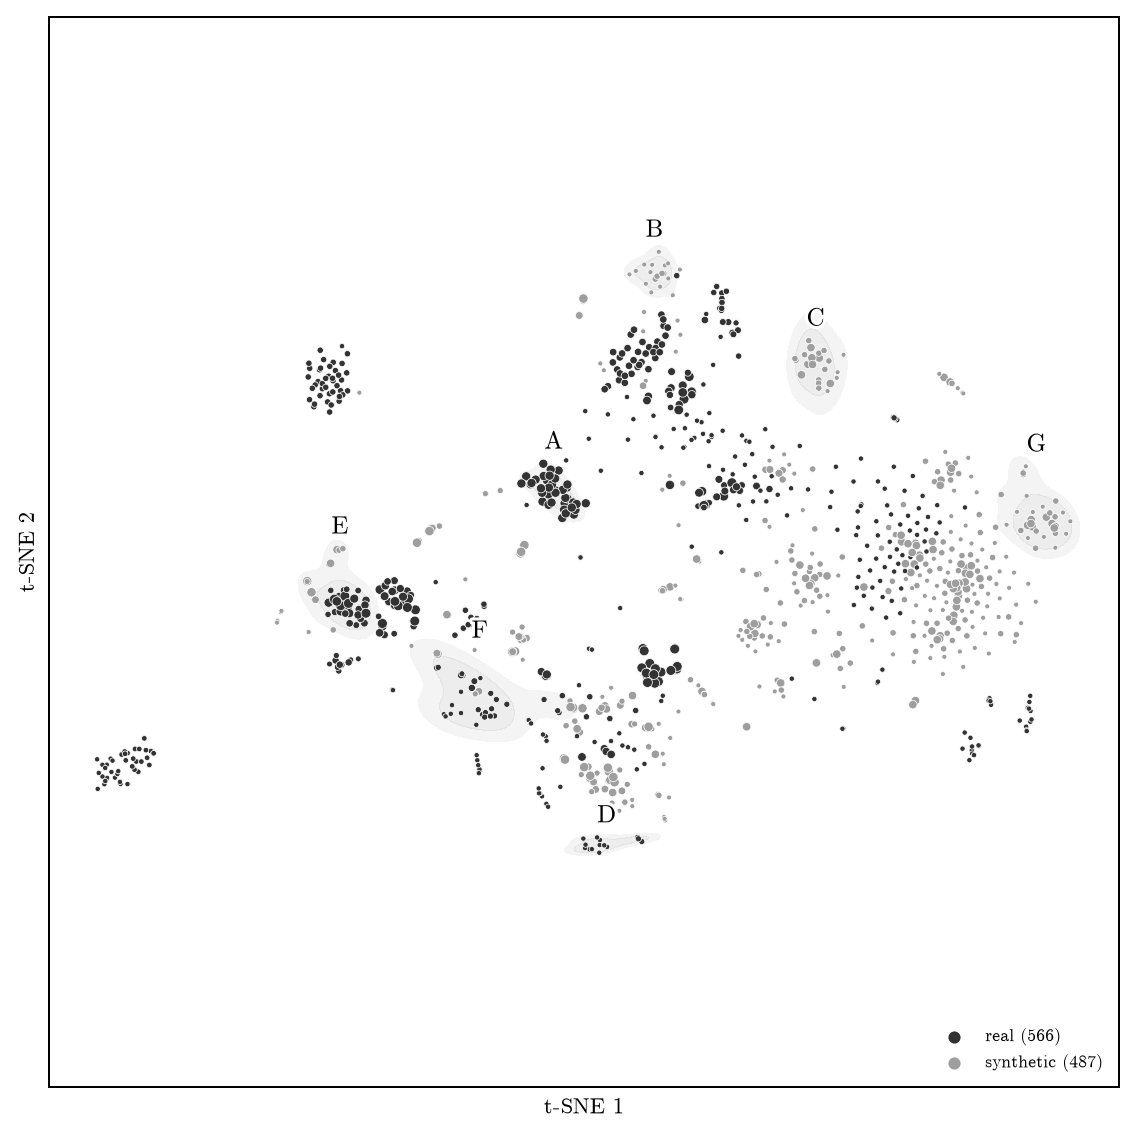

primary-p30-x1-pca: R5 0.487, R15 0.495, R50 0.461; seed 15-NN overlap 0.948; subsample 15-NN 0.720. Shading: 50/80% KDE mass of each lettered cluster's map points (display only).


In [9]:
CHOSEN = "primary-p30-x1-pca"
xy = first(CHOSEN)
fig, ax = plt.subplots(figsize=(6.2, 6.2))
ta.plot_atlas(ax, xy, meta, labels, LETTERS, size=1.0)
ax.set(xlabel="t-SNE 1", ylabel="t-SNE 2")
handles = [ax.scatter([], [], s=30, c=c, edgecolors=e, linewidths=.6, label=l)
           for c, e, l in [("0.2", "white", f"real ({(meta.origin == 'real').sum()})"), ("0.62", "white", f"synthetic ({(meta.origin == 'synthetic').sum()})")]]
ax.legend(handles=handles, loc="lower right", fontsize=7)
for ext in ["svg", "pdf", "png"]:
    fig.savefig(FIGURES / f"atlas-map.{ext}", dpi=600 if ext == "png" else None)
plt.show()
g = grid.loc[CHOSEN]
print(f"{CHOSEN}: R5 {g.recall5_full:.3f}, R15 {g.recall15_full:.3f}, R50 {g.recall50_full:.3f}; seed 15-NN overlap {g.seed_nn15_overlap:.3f}; "
      f"subsample 15-NN {g.subsample_nn15_vs_full_map:.3f}. Shading: 50/80% KDE mass of each lettered cluster's map points (display only).")

## 6. Inspection

The first figure works without a kernel: hover shows dataset, source, origin, M, T and Ward-40 cluster (letter if a candidate). The second needs a live kernel: click a point to show its metadata and robust-scaled heatmap. The standalone explorer (section 9) adds cluster browsing, heatmap cards and selection export.

In [10]:
ta.hover_figure(xy, meta, labels, LETTERS, "Chosen map · hover for metadata").show()

In [11]:
ta.inspection_widget(xy, meta, labels, LETTERS, corpus["arrays"])

    'data': [{'hovertemplate': '%{text}<extra></extra>',
              'marker':…

## 7. Feature-space clusters

Clusters are fitted on the full-rank primary geometry and only displayed on the map. Ward linkage is deterministic and nested across resolutions. Stability uses Hennig's (2007) cluster-wise Jaccard under 50 subsets that keep a random 80% of *parent recordings* (688 parent keys: M/T variants and nested windows of one simulation, price and log-return versions of one market window, region subsets of one subject, and all epidemic chunks share a key). By Hennig's rule of thumb, ≥ 0.75 is stable and < 0.5 dissolved. Ward is clearly more stable than K-means at the same k, and k = 40 maximises the number of stable groups at a usable size. Global separation is weak at every k (median per-cluster silhouette 0.09–0.15), so no natural cluster count is claimed.

In [12]:
C = R["clusters"]
summary = C.groupby("partition").agg(clusters=("cluster", "size"), median_jaccard=("jaccard_mean", "median"),
                                     stable_075=("jaccard_mean", lambda j: int((j >= .75).sum())),
                                     rows_in_stable=("size", lambda s: int(s[C.loc[s.index, "jaccard_mean"] >= .75].sum())),
                                     median_silhouette=("silhouette_full", "median"))
display(summary.round(3))
W = C[C.partition == "ward40"].copy()
W[["composition", "origin"]] = W.apply(lambda r: pd.Series(ta.classify(r)), axis=1)
W["candidate"] = W.cluster.map(LETTERS).fillna("")
W.sort_values("jaccard_mean", ascending=False)[["cluster", "candidate", "size", "parents", "composition", "origin", "silhouette_full",
                                               "jaccard_mean", "dissolved_fraction", "M_range", "T_range", "source_mix"]].round(2)

,clusters,median_jaccard,stable_075,rows_in_stable,median_silhouette
partition,,,,,
kmeans20,20,0.584,4,343,0.146
kmeans40,40,0.630,15,497,0.130
kmeans60,60,0.633,16,398,0.120
ward20,20,0.712,9,458,0.087
ward40,40,0.802,25,571,0.131
ward60,60,0.796,35,576,0.113


,cluster,candidate,size,parents,composition,origin,silhouette_full,jaccard_mean,dissolved_fraction,M_range,T_range,source_mix
42,22,,6,1,homogeneous,synthetic,0.35,1.00,0.00,16–25,100–1000,Wave 2D 6
23,3,,3,1,homogeneous,synthetic,0.28,1.00,0.00,5–5,501–2001,Oscillator sync 3
51,31,,10,1,homogeneous,real,0.23,1.00,0.00,8–14,567–567,Epidemic incidence 10
55,35,A,36,36,homogeneous,real,0.31,0.98,0.00,24–24,51–51,NATOPS 36
36,16,,7,1,homogeneous,synthetic,0.26,0.98,0.00,5–20,101–2001,Oscillator sync 7
37,17,,8,1,homogeneous,synthetic,0.23,0.97,0.00,5–20,101–2001,Oscillator sync 8
28,8,,26,26,homogeneous,real,0.12,0.96,0.00,6–6,100–100,BasicMotions 26
50,30,,41,40,heterogeneous,mixed,0.31,0.94,0.00,5–10,400–1000,HandMovementDirection 39; CML 2
38,18,,11,2,homogeneous,synthetic,0.11,0.91,0.08,5–20,101–2001,Oscillator sync 11
49,29,,20,20,homogeneous,real,0.17,0.91,0.04,7–7,1152–1152,SelfRegulationSCP2 20


### Candidate selection

Selection favoured (i) Hennig-stable groups (Jaccard ≥ 0.75), (ii) several parent recordings, and (iii) coverage of the narrative categories. Composition (one source family or several) and origin (real, synthetic, mixed) are recorded separately. Robustness columns: best-match Jaccard in K-means k=40 (method) and in a Ward-40 refit on the 9,313 complete features (imputation). `cross_source_nn5` is the fraction of members' five nearest full-space neighbours that come from a different source family; it is high only where sources genuinely interleave.

Runners-up not lettered: HandMovementDirection MEG with two windows of one coupled-map intermittency simulation (Jaccard 0.94, silhouette 0.31, but one synthetic parent); SelfRegulationSCP1/SCP2 EEG (two stable homogeneous groups); a 149-member group of uncoupled or weakly coupled linear-Gaussian processes (VAR, VMA, IID noise, strongly coupled phase oscillators; Jaccard 0.87).

In [13]:
keep = A["keep_indices"]
table, readings = ta.candidate_table({c: v for c, v in CANDIDATES.items()}, labels, W, A, meta, xy, corpus, keep)
expected = {"A": "NATOPS", "B": "NetSim fMRI", "C": "CML", "D": "Cricket", "E": "PEMS-SF", "F": "ArticularyWordRecognition", "G": "IID noise"}
assert all(t.sources.startswith(expected[t.letter]) for t in table.itertuples()), "cluster ids changed; re-select candidates"
table.drop(columns=["cluster"]).round(2)

,letter,title,composition,origin,size,parents,sources,silhouette_full,silhouette_map,jaccard,jaccard_kmeans40,jaccard_complete_features,cross_source_nn5,M,T,families_up,families_down
0,A,NATOPS gestures,homogeneous,real,36,36,NATOPS 36,0.31,0.77,0.98,0.86,0.92,0.00,24–24,51–51,basic × basic +0.20; causal × distance +0.16,causal × spectral -0.43; basic × causal -0.34
1,B,NetSim fMRI simulations,homogeneous,synthetic,20,19,NetSim fMRI 20,0.12,0.71,0.90,0.77,0.62,0.08,5–10,2000–2000,basic × causal +0.19; distance × misc +0.05,basic × basic -0.31; misc × spectral -0.24
2,C,Coupled map lattices + synthetic weather,heterogeneous,synthetic,25,14,CML 14; TestWEATH 9; Oscillator sync 1; VAR 1,0.14,0.64,0.77,0.92,0.72,0.30,5–20,100–1000,basic × spectral +0.20; causal × misc +0.16,causal × infotheory -0.23; causal × spectral -0.19
3,D,Cricket accelerometry + ForEx prices,heterogeneous,real,15,15,Cricket 11; ForEx 4,0.14,0.46,0.85,0.69,0.94,0.13,6–9,134–1197,basic × causal +0.33; infotheory × infotheory +0.13,spectral × spectral -0.37; causal × misc -0.36
4,E,PEMS-SF traffic + LEGION oscillators + geometric Brownian motion,heterogeneous,mixed,41,33,PEMS-SF 29; LEGION 7; Brownian motion 5,0.10,0.32,0.72,0.49,0.70,0.16,5–29,144–2000,basic × spectral +0.79; basic × basic +0.65,causal × spectral -0.60; causal × misc -0.34
5,F,"Trending series: articulation, cricket, Brownian motion, stock prices",heterogeneous,mixed,37,33,ArticularyWordRecognition 14; Cricket 8; Brownian motion 5; DJIA 4; S&P 500 3; EigenWorms 2; HCP rs-fMRI 1,0.04,0.21,0.76,0.64,0.68,0.52,6–25,100–3000,basic × basic +0.69; causal × distance +0.17,basic × causal -0.39; spectral × spectral -0.29
6,G,Heavy-tailed noise + TestWEATH with 999 missing-value codes,heterogeneous,synthetic,32,12,IID noise 22; TestWEATH 10,0.05,0.68,0.90,0.94,1.00,0.24,5–20,100–2000,spectral × spectral +0.64; causal × spectral +0.63,basic × basic -0.49; basic × spectral -0.29


In [14]:
axes_table = pd.DataFrame({f"{t.letter}": readings[t.cluster]["axes"] for t in table.itertuples()})
axes_table["corpus median"] = readings[table.cluster.iloc[0]]["corpus_axes"]
print("Median z of the case-study SPI pairs (agreement between the two statistics across ordered entries):")
axes_table.round(2)

Median z of the case-study SPI pairs (agreement between the two statistics across ordered entries):


,A,B,C,D,E,F,G,corpus median
r–ρ (linear vs monotone),0.98,1.00,1.00,0.98,0.79,0.97,0.28,0.97
r–MI (linear vs general),0.31,0.96,0.63,-0.36,0.74,0.34,0.06,0.30
r–max xcorr (zero lag vs best lag),0.79,1.00,0.54,0.73,0.96,0.88,0.03,0.59
r–coherence (time vs frequency),0.39,0.94,0.69,-0.24,0.56,0.34,-0.02,0.26
Euclid–DTW (aligned vs warped shape),0.91,0.11,0.30,0.69,0.53,0.90,-0.02,0.54


In [15]:
def show_candidate(letter, n=8):
    t = table.set_index("letter").loc[letter]
    members = np.flatnonzero(labels == t.cluster)
    reps = ta.representatives(members, A["full_distances"], meta, n=n)
    fig = plt.figure(figsize=(10, 3.1))
    sub = fig.subfigures(1, 2, width_ratios=[1, 2.6])
    ax = sub[0].subplots()
    ta.plot_atlas(ax, xy, meta, np.where(labels == t.cluster, labels, -1), {t.cluster: letter}, size=.35)
    ax.scatter(*xy[reps].T, s=22, facecolors="none", edgecolors="k", linewidths=.7, zorder=4)
    fig.suptitle(f"{letter} · {t.title}", fontsize=9, x=.01, ha="left")
    cols = 4
    grid_axes = sub[1].subplots(int(np.ceil(len(reps) / cols)), cols, squeeze=False)
    for a, r in zip(grid_axes.flat, reps):
        m = meta.iloc[r]
        ta.heatmap(a, corpus["arrays"][m.dataset], f"{m.source} · {m.origin[0]} · {m.M}×{m['T']}")
    for a in grid_axes.flat[len(reps):]:
        a.axis("off")
    for ext in ["svg", "pdf", "png"]:
        fig.savefig(FIGURES / f"candidate-{letter}.{ext}", dpi=300 if ext == "png" else None)
    plt.show()
    frame = readings[t.cluster]["frame"]
    top = frame.reindex(frame.effect.abs().sort_values(ascending=False).index).head(6)
    print(f"{t.composition} · {t.origin} · {t['size']} MTS / {t.parents} parents · silhouette full {t.silhouette_full:.2f}, map {t.silhouette_map:.2f} · "
          f"Jaccard {t.jaccard:.2f} (K-means {t.jaccard_kmeans40:.2f}, complete features {t.jaccard_complete_features:.2f}) · cross-source 5-NN {t.cross_source_nn5:.2f}")
    print(f"Sources: {t.sources}\nSPI-family blocks with higher agreement than the corpus: {t.families_up}; lower: {t.families_down}")
    display(top[["spi_a", "spi_b", "effect", "cluster_median", "corpus_median"]].round(2))

In [16]:
descriptors = pd.DataFrame([ta.raw_descriptors(corpus["arrays"][n]) for n in meta.dataset])
check_table = descriptors.groupby(labels).median().loc[table.cluster]
check_table.index = table.letter
check_table.loc["corpus"] = descriptors.median()
print("Raw-series checks (medians over members): lag-1 autocorrelation, linear-trend R², share of negative r among each "
      "recording's top-quartile |r| edges, first-PC variance share of z-scored channels, share of repeated consecutive values, max robust |z|.")
check_table.round(2)

Raw-series checks (medians over members): lag-1 autocorrelation, linear-trend R², share of negative r among each recording's top-quartile |r| edges, first-PC variance share of z-scored channels, share of repeated consecutive values, max robust |z|.


,lag1,trend_r2,negative_share_strong,pc1_share,repeat_fraction,max_robust_z
letter,,,,,,
A,0.96,0.07,0.11,0.62,0.00,8.94
B,0.36,0.00,0.00,0.40,0.00,4.47
C,-0.66,0.00,0.17,0.30,0.00,3.81
D,0.99,0.09,0.75,0.49,0.24,25.63
E,0.95,0.09,0.00,0.68,0.01,15.26
F,0.99,0.47,0.09,0.56,0.25,6.38
G,-0.01,0.00,0.50,0.12,0.00,2091.50
corpus,0.55,0.01,0.31,0.37,0.00,4.78


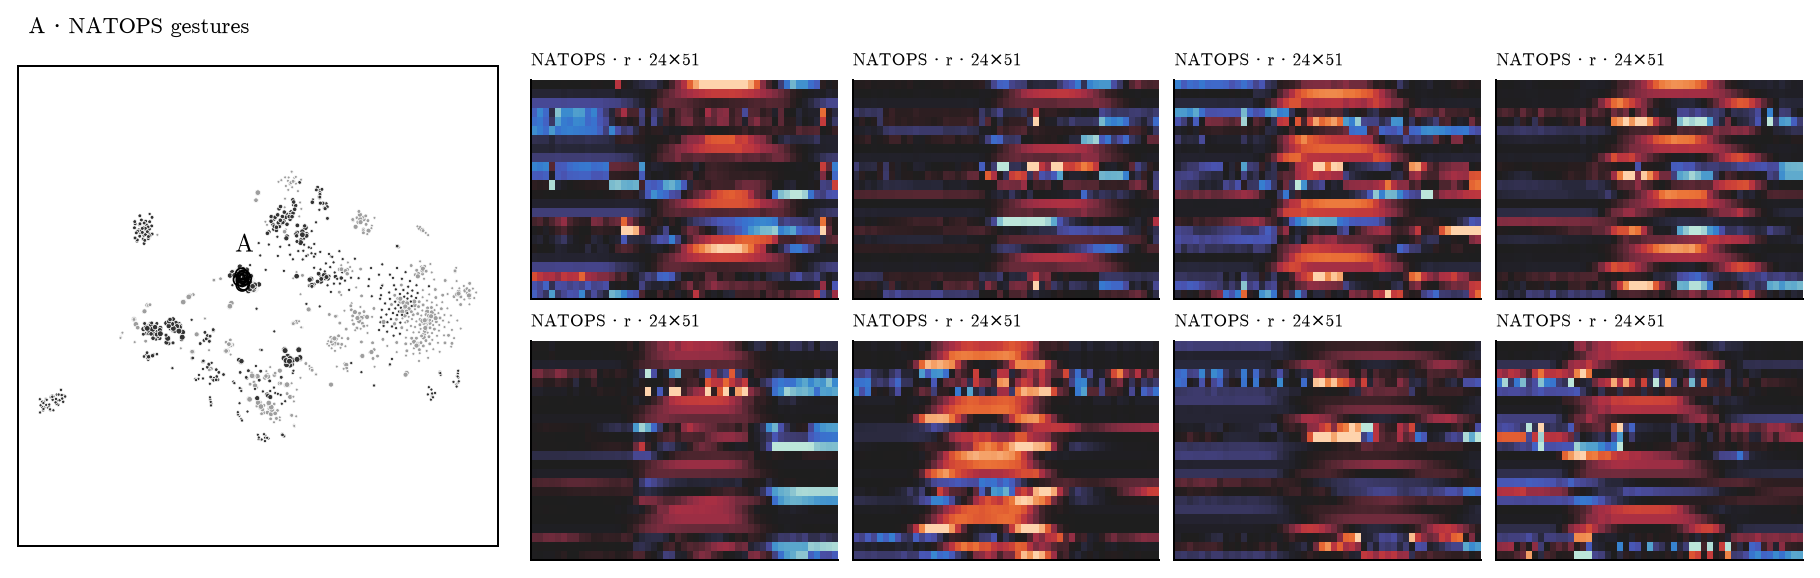

homogeneous · real · 36 MTS / 36 parents · silhouette full 0.31, map 0.77 · Jaccard 0.98 (K-means 0.86, complete features 0.92) · cross-source 5-NN 0.00
Sources: NATOPS 36
SPI-family blocks with higher agreement than the corpus: basic × basic +0.20; causal × distance +0.16; lower: causal × spectral -0.43; basic × causal -0.34


,spi_a,spi_b,effect,cluster_median,corpus_median
2388,prec-sq_EmpiricalCovariance,prec-sq_ShrunkCovariance,-3.26,0.15,0.99
11778,pdist_euclidean,bary-sq_euclidean_mean,2.76,-0.97,-1.00
11759,pdist_euclidean,pdist_cosine,-2.76,0.97,1.00
66,cov_EmpiricalCovariance,pdist_euclidean,2.76,-0.97,-1.00
671,cov_ShrunkCovariance,pdist_euclidean,2.76,-0.97,-1.00
8135,corr_spearman_tau-10,corr_kendall_tau-10,-2.42,0.98,1.00


In [17]:
show_candidate("A")

**A · NATOPS gestures: homogeneous, real.** 36 recordings of one UEA gesture dataset (24 channels, 51 samples each), each its own parent. It is the most stable group in the corpus and survives the method and preprocessing changes. Signature: aligned and warped shape similarity agree (Euclid–DTW 0.91 vs 0.54 corpus), zero-lag and best-lag correlation agree (0.79 vs 0.59), and the channels are smooth (lag-1 0.96). Its largest single contrasts are disagreements among precision (partial-correlation) estimators, but these do not hold the group together: without the 1,612 precision-estimator pairs it is unchanged (silhouette 0.31, Ward-40 refit Jaccard 1.00). A is the only source at 24 × 51, so no control fully separates its size from its source. It still exceeds all 1,000 size-matched random sets (see the [size-control notebook](zenodo_1053_mt_control_261021.ipynb)). Use it as the "one source, one signature" anchor and disclose its single size.

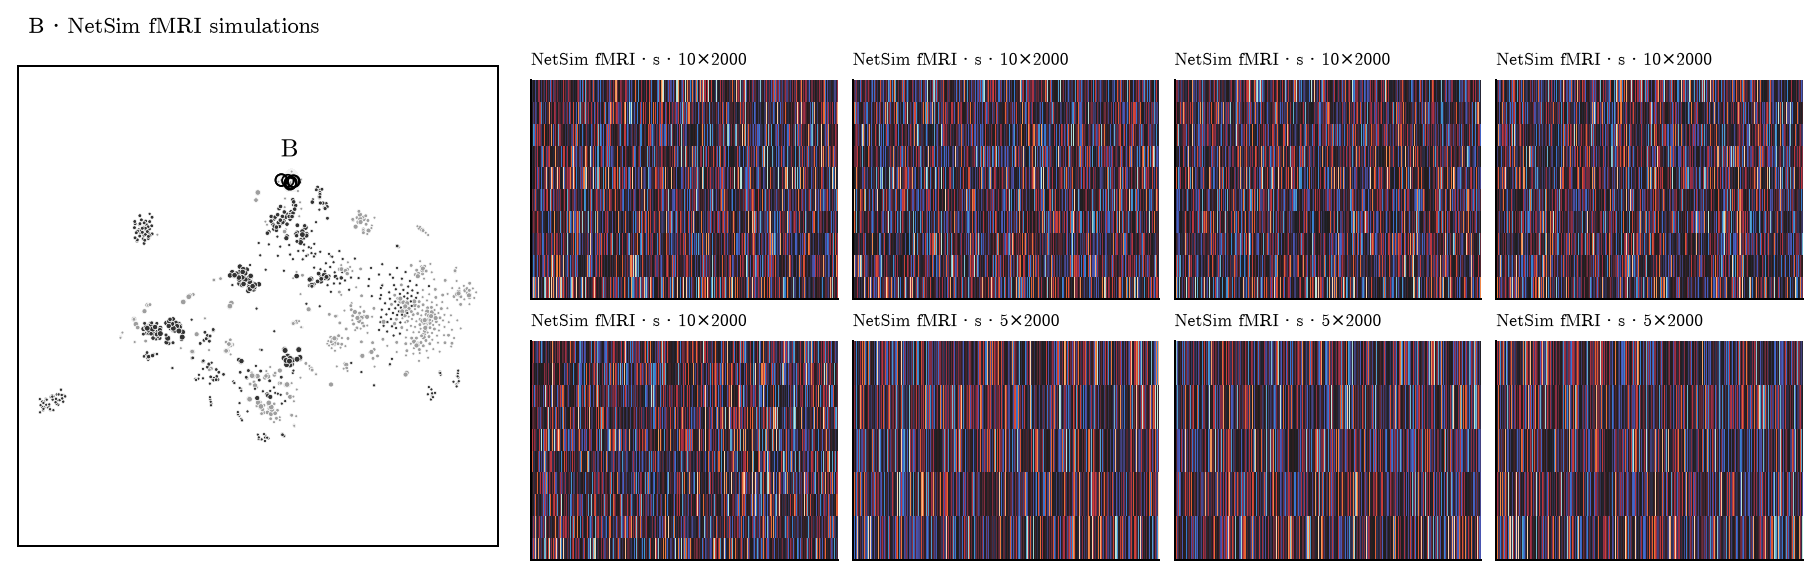

homogeneous · synthetic · 20 MTS / 19 parents · silhouette full 0.12, map 0.71 · Jaccard 0.90 (K-means 0.77, complete features 0.62) · cross-source 5-NN 0.08
Sources: NetSim fMRI 20
SPI-family blocks with higher agreement than the corpus: basic × causal +0.19; distance × misc +0.05; lower: basic × basic -0.31; misc × spectral -0.24


,spi_a,spi_b,effect,cluster_median,corpus_median
2213,prec_ShrunkCovariance,corr_spearman_tau-2,2.71,0.57,-0.55
2227,prec_ShrunkCovariance,corr_kendall_tau-2,2.69,0.56,-0.56
2199,prec_ShrunkCovariance,corr_pearson_tau-2,2.69,0.53,-0.59
4144,corr_pearson_tau-2,pdist_cityblock,2.68,0.61,-0.87
4147,corr_pearson_tau-2,pdist_canberra,2.67,0.58,-0.78
6647,corr_spearman_tau-2,pdist_braycurtis,2.67,0.60,-0.81


In [18]:
show_candidate("B")

**B · NetSim fMRI simulations: homogeneous, synthetic.** 20 simulations (19 parents; `sim1` and `sim21` are identical arrays). The four r-based case axes are near 1 (r–ρ 1.00, r–MI 0.96, r–max xcorr 1.00, r–coherence 0.94), and no strong edge is negative. Reading: positive, contemporaneous and essentially linear–Gaussian dependence, which every family of statistics reports alike. Low Euclid–DTW agreement (0.11) fits short-memory fluctuations (lag-1 0.36) that warping cannot align. The refit on complete features is weaker (0.62), so part of the separation rests on imputed features.

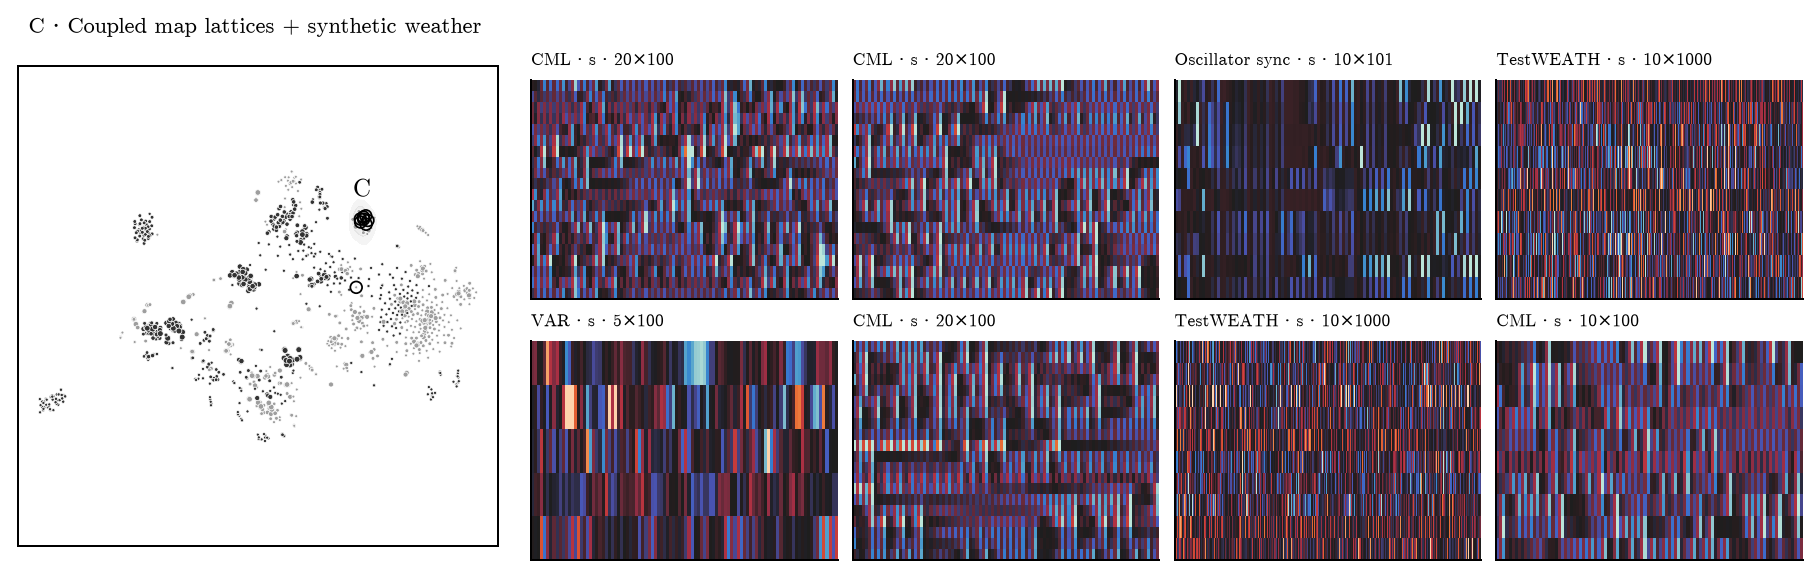

heterogeneous · synthetic · 25 MTS / 14 parents · silhouette full 0.14, map 0.64 · Jaccard 0.77 (K-means 0.92, complete features 0.72) · cross-source 5-NN 0.30
Sources: CML 14; TestWEATH 9; Oscillator sync 1; VAR 1
SPI-family blocks with higher agreement than the corpus: basic × spectral +0.20; causal × misc +0.16; lower: causal × infotheory -0.23; causal × spectral -0.19


,spi_a,spi_b,effect,cluster_median,corpus_median
3969,corr_pearson_tau-1,xpdist_euclidean_tau-1_mean_rmse,3.76,0.53,-0.97
3968,corr_pearson_tau-1,xpdist_euclidean_tau-1_min_rmse,3.72,0.51,-0.95
6482,corr_spearman_tau-1,xpdist_euclidean_tau-1_mean_rmse,3.38,0.54,-0.85
8799,corr_kendall_tau-1,xpdist_euclidean_tau-1_mean_rmse,3.36,0.54,-0.85
6481,corr_spearman_tau-1,xpdist_euclidean_tau-1_min_rmse,3.32,0.53,-0.84
8798,corr_kendall_tau-1,xpdist_euclidean_tau-1_min_rmse,3.30,0.54,-0.83


In [19]:
show_candidate("C")

**C · Coupled map lattices and synthetic weather: heterogeneous, synthetic.** Kaneko-type logistic-map lattices in pattern-selection, intermittency and spatiotemporal-chaos regimes (14 windows from 3 simulations) sit with 9 TestWEATH series (and one oscillator and one VAR window). Half of the TestWEATH members' nearest neighbours are lattice windows. Signature: lagged statistics behave unlike the rest of the corpus. Lag-1 correlation and lag-1 cross-distance agree (z 0.53, against −0.97 corpus-wide), and Euclid–DTW agreement is low (0.30). The raw check identifies the shared trait as short-lag anti-persistence. Lattice channels alternate sign step to step (lag-1 −0.66 to −0.91, the period-2 flip of the logistic map at these parameters), and the TestWEATH members inside C lean negative (median ≈ −0.14) whereas those outside lean positive (+0.14). The mechanisms differ; the shared organisation is alternating, short-lag dependence. The lattice windows are nested M/T variants, not independent replicates.

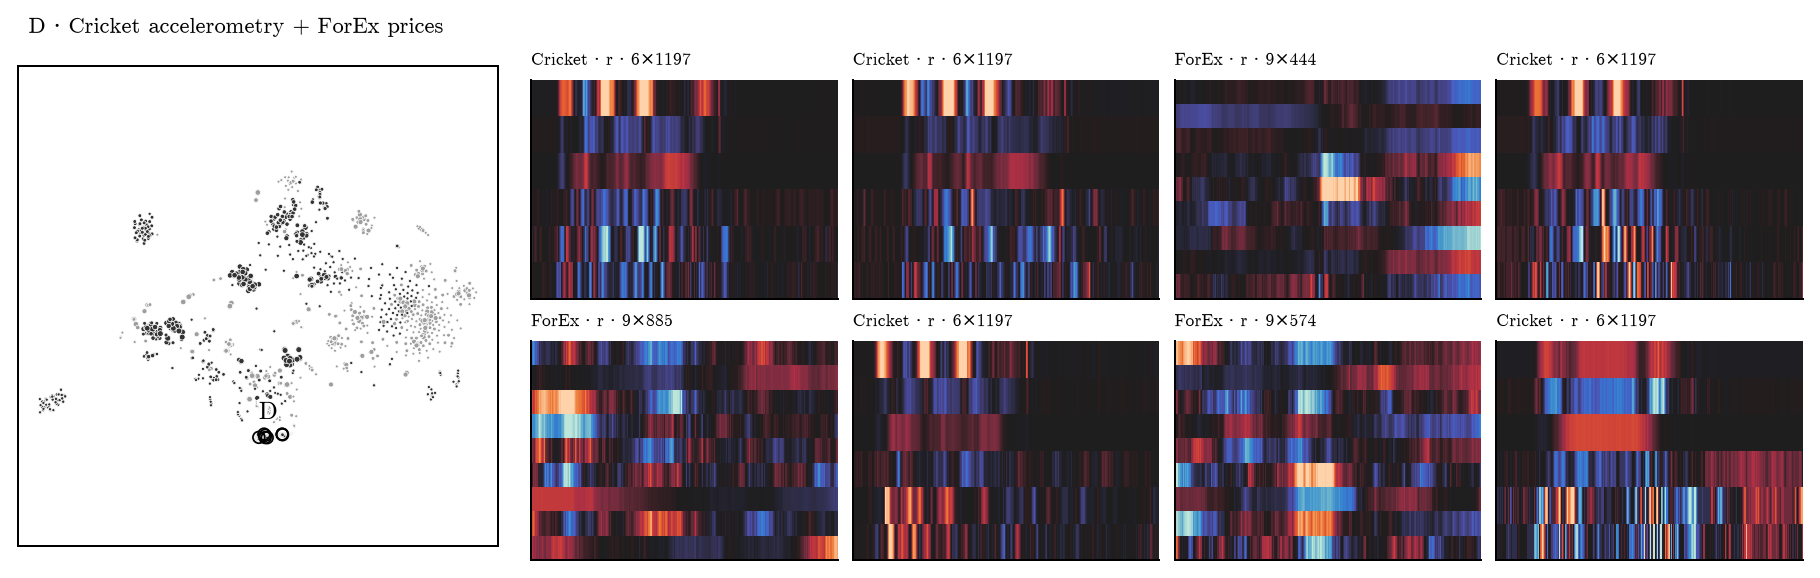

heterogeneous · real · 15 MTS / 15 parents · silhouette full 0.14, map 0.46 · Jaccard 0.85 (K-means 0.69, complete features 0.94) · cross-source 5-NN 0.13
Sources: Cricket 11; ForEx 4
SPI-family blocks with higher agreement than the corpus: basic × causal +0.33; infotheory × infotheory +0.13; lower: spectral × spectral -0.37; causal × misc -0.36


,spi_a,spi_b,effect,cluster_median,corpus_median
12461,pdist_braycurtis,bary-sq_sgddtw_mean,2.95,-0.40,-0.94
13982,bary_dtw_mean,bary_sgddtw_mean,-2.94,0.29,0.77
2143,prec_MinCovDet,dcoh_multitaper_mean_fs-1_fmin-0_fmax-0-25,2.70,0.66,-0.07
1950,prec_EllipticEnvelope,dcoh_multitaper_mean_fs-1_fmin-0_fmax-0-25,2.69,0.66,-0.07
2155,prec_MinCovDet,gpdcoh_multitaper_mean_fs-1_fmin-0_fmax-0-25,2.67,0.69,-0.07
1962,prec_EllipticEnvelope,gpdcoh_multitaper_mean_fs-1_fmin-0_fmax-0-25,2.66,0.69,-0.07


In [20]:
show_candidate("D")

**D · Cricket accelerometry and ForEx prices: heterogeneous, real.** Wrist-accelerometer recordings of umpire signals (Cricket classes 3 and 6) and four foreign-exchange price windows (levels, not log-returns). The two sources form adjacent sub-groups rather than interleaving (cross-source 5-NN 0.13), and the group is less stable under K-means (0.69). Signature: signed linear correlation *disagrees* with unsigned dependence measures (r–MI −0.36, r–coherence −0.24, both positive corpus-wide). The raw check confirms the reading: 75% of each recording's strongest edges are negative, against 27% corpus-wide (Cricket 0.75, ForEx 0.61). The shared organisation is anti-correlation-dominated coupling. Plausible but unverified sources: opposed sensor axes or limbs, and inversely quoted currency pairs. Cricket also contains long constant runs (25% repeated values), which leave Kraskov MI undefined; the group survives the imputation-free refit (0.94), so this is not an imputation artefact, but ties may still shape some estimators.

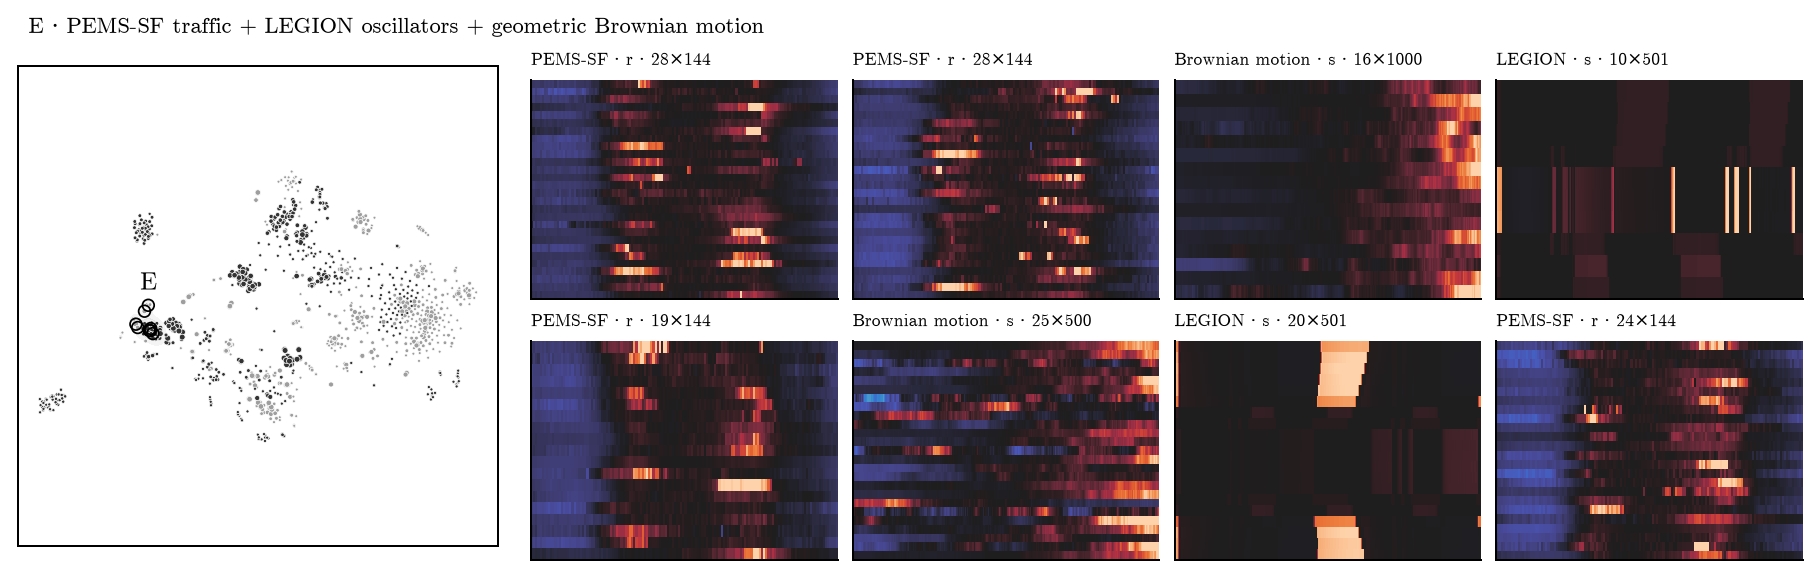

heterogeneous · mixed · 41 MTS / 33 parents · silhouette full 0.10, map 0.32 · Jaccard 0.72 (K-means 0.49, complete features 0.70) · cross-source 5-NN 0.16
Sources: PEMS-SF 29; LEGION 7; Brownian motion 5
SPI-family blocks with higher agreement than the corpus: basic × spectral +0.79; basic × basic +0.65; lower: causal × spectral -0.60; causal × misc -0.34


,spi_a,spi_b,effect,cluster_median,corpus_median
16327,xme_kernel_W-0.5_k10,cohmag_multitaper_max_fs-1_fmin-0_fmax-0-25,-1.93,-0.53,-0.07
16360,xme_kernel_W-0.5_k10,ppc_multitaper_max_fs-1_fmin-0_fmax-0-25,-1.91,-0.47,-0.06
16342,xme_kernel_W-0.5_k10,plv_multitaper_max_fs-1_fmin-0_fmax-0-25,-1.90,-0.47,-0.06
12473,pdist_braycurtis,xme_kernel_W-0.5_k10,1.90,0.60,0.03
5809,corr_pearson_tau-10,xme_kernel_W-0.5_k10,-1.89,-0.53,-0.05
4180,corr_pearson_tau-2,xme_kernel_W-0.5_k10,-1.89,-0.58,-0.04


In [21]:
show_candidate("E")

**E · Traffic, LEGION oscillators and geometric Brownian motion: heterogeneous, mixed.** PEMS-SF freeway occupancy (29 days), LEGION relaxation-oscillator networks (7 windows of 3 configurations) and geometric Brownian motion (5). The neighbourhoods interleave: LEGION members' nearest neighbours are mostly traffic days. Signature: linear statistics agree with spectral ones far more than usual (basic × spectral block +0.79 SD), r–max xcorr is 0.96, and r–ρ is lower than usual (0.79 vs 0.97). Raw check: a strong common mode (first-PC share 0.68 vs 0.37) and no negative strong edges. Reading: dependence carried by large, shared, slow excursions across channels (daily occupancy waves, synchronous relaxation jumps, common drift), so zero-lag, lagged and spectral linear measures coincide while rank and linear measures part where the excursions are nonlinear in amplitude. This is the clearest real–synthetic co-location, but a less stable one: Jaccard 0.72 (just under Hennig's 0.75), and it is method-dependent (K-means 0.49). Four members carry > 20% imputed entries; the complete-feature refit keeps 0.70.

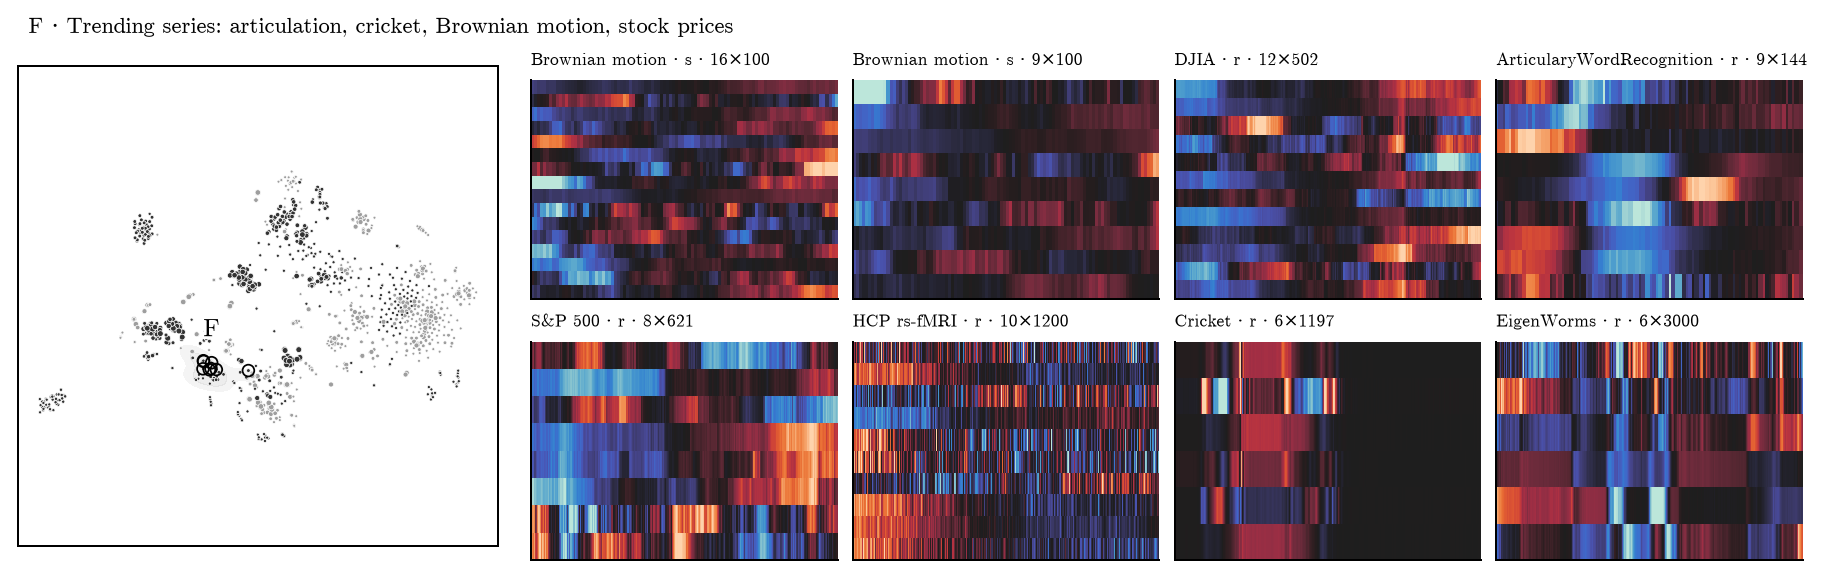

heterogeneous · mixed · 37 MTS / 33 parents · silhouette full 0.04, map 0.21 · Jaccard 0.76 (K-means 0.64, complete features 0.68) · cross-source 5-NN 0.52
Sources: ArticularyWordRecognition 14; Cricket 8; Brownian motion 5; DJIA 4; S&P 500 3; EigenWorms 2; HCP rs-fMRI 1
SPI-family blocks with higher agreement than the corpus: basic × basic +0.69; causal × distance +0.17; lower: basic × causal -0.39; spectral × spectral -0.29


,spi_a,spi_b,effect,cluster_median,corpus_median
14584,bary-sq_euclidean_max,bary-sq_sgddtw_max,-2.13,-0.38,0.96
13861,bary_euclidean_max,bary_sgddtw_max,-2.06,-0.28,0.95
21671,coint_johansen_max_eig_stat_order-0_ardiff-1,coint_johansen_max_eig_stat_order-1_ardiff-1,-1.97,0.75,1.00
10611,corr_kendall_tau-20,xcorr_max_sig-True,1.93,0.88,0.07
21686,coint_johansen_trace_stat_order-0_ardiff-1,coint_johansen_trace_stat_order-1_ardiff-1,-1.92,0.83,1.00
8462,corr_spearman_tau-20,xcorr_max_sig-True,1.91,0.88,0.08


In [22]:
show_candidate("F")

**F · Trending series: heterogeneous, mixed.** Articulatory word-recognition sensors, cricket accelerometry, arithmetic Brownian motion, DJIA and S&P 500 price levels, EigenWorms posture and one HCP rs-fMRI recording. Neighbourhoods interleave most of all candidates (cross-source 5-NN 0.52), but overall separation is weak (silhouette 0.04): this is a region of a continuum, not an island. Signature: lag-20 rank correlation agrees with maximum cross-correlation (0.88 vs 0.07 corpus), and cointegration statistics disagree across model orders. Raw check: linear-trend R² 0.47 (corpus 0.01), lag-1 0.99. Reading: dependence dominated by persistent, near-integrated components. This is the regime in which correlations between trending series are large irrespective of coupling (Yule 1926; Granger & Newbold 1974). Different mechanisms, one shared and largely nonstationarity-driven organisation; the log-return versions of the same DJIA and S&P 500 windows fall in a different group (cluster 25), as that reading predicts.

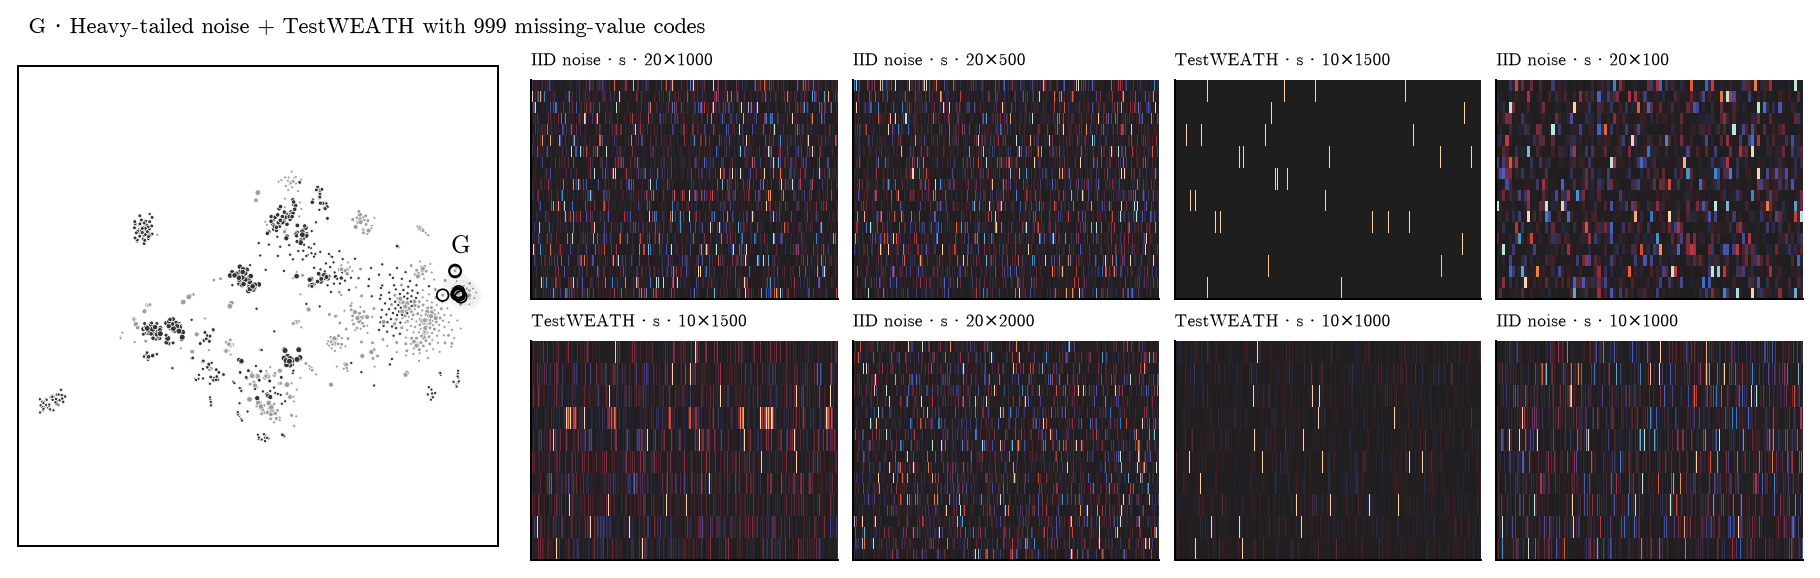

heterogeneous · synthetic · 32 MTS / 12 parents · silhouette full 0.05, map 0.68 · Jaccard 0.90 (K-means 0.94, complete features 1.00) · cross-source 5-NN 0.24
Sources: IID noise 22; TestWEATH 10
SPI-family blocks with higher agreement than the corpus: spectral × spectral +0.64; causal × spectral +0.63; lower: basic × basic -0.49; basic × spectral -0.29


,spi_a,spi_b,effect,cluster_median,corpus_median
11758,pdist_euclidean,pdist_cityblock,-4.50,0.15,0.97
672,cov_ShrunkCovariance,pdist_cityblock,4.44,-0.15,-0.96
11897,pdist_cityblock,pdist_cosine,-4.44,0.15,0.96
11916,pdist_cityblock,bary-sq_euclidean_mean,4.44,-0.15,-0.96
67,cov_EmpiricalCovariance,pdist_cityblock,4.44,-0.15,-0.96
11900,pdist_cityblock,pdist_braycurtis,-4.19,0.18,0.95


In [23]:
show_candidate("G")

**G · Heavy-tailed noise and TestWEATH with missing-value codes: heterogeneous, synthetic, cautionary.** Uncoupled Student-t and Cauchy noise (22 M/T variants of 2 generators) with all ten `TestWEATHmiss` series. Those series code missing values as 999.0 (about 1% of entries; raw max robust |z| ≈ 2,000); no other archive member does. Signature: r–ρ agreement collapses (0.28 vs 0.97) and Euclidean and city-block distances disagree; every other axis is near 0, as for uncoupled noise. The representation reads the character correctly: outlier-dominated, otherwise absent dependence. Here that character is an observation artefact, not dynamics. Keep it as the example that co-location reports a shared dependence-measurement signature, whatever produced it.

### How the map draws the candidates

Feature-space membership is fixed; only the display changes. The table gives each candidate's 2-D silhouette in alternative maps. The full-space silhouette is the same in every column. Larger 2-D values under ρ = 2 or perplexity 10 are the map's doing, not stronger feature-space separation.

In [24]:
from sklearn.metrics import silhouette_samples
from scipy.spatial.distance import pdist, squareform
display_keys = {"chosen (p30, ρ1)": CHOSEN, "PCA50 (p30, ρ1)": "pca50-p30-x1-pca", "p30, ρ2": "primary-p30-x2-pca",
                "p10, ρ2": "primary-p10-x2-pca", "PC1–PC2": "pc1-pc2"}
shown = {}
for name, key in display_keys.items():
    s = silhouette_samples(squareform(pdist(first(key))), labels, metric="precomputed")
    shown[name] = [s[labels == c].mean() for c in table.cluster]
shown = pd.DataFrame(shown, index=table.letter)
shown.insert(0, "full space", table.set_index("letter").silhouette_full)
shown.round(2)

,full space,"chosen (p30, ρ1)","PCA50 (p30, ρ1)","p30, ρ2","p10, ρ2",PC1–PC2
letter,,,,,,
A,0.31,0.77,0.77,0.95,0.86,0.04
B,0.12,0.71,0.77,0.95,0.91,0.48
C,0.14,0.64,0.74,0.56,0.58,-0.28
D,0.14,0.46,0.57,0.54,0.50,0.07
E,0.10,0.32,0.35,0.46,0.52,-0.21
F,0.04,0.21,0.19,0.24,0.28,-0.25
G,0.05,0.68,0.68,0.76,0.76,-0.08


## 8. Explorer v3

The standalone page (`results/zenodo_7118947/tsne-261021/index.html`, from the template `research/zenodo/atlas/zenodo_gallery_v3.html`) carries the chosen map, the PCA50 and ρ = 2 maps for comparison, and PC1–PC2. Each map keeps the Ward-40 memberships fixed. Heatmap thumbnails are embedded, so the page works offline; the native PNG/SVG links need the v1 asset folder `results/zenodo_7118947/visual-exploration/` beside it.

In [25]:
NOTES = {'A': '36 recordings of one UEA gesture dataset (24 channels, 51 samples each), each its own parent. It is the most stable group in the corpus and survives the method and preprocessing changes. Signature: aligned and warped shape similarity agree (Euclid–DTW 0.91 vs 0.54 corpus), zero-lag and best-lag correlation agree (0.79 vs 0.59), and the channels are smooth (lag-1 0.96). Its largest single contrasts are disagreements among precision (partial-correlation) estimators, but these do not hold the group together: without the 1,612 precision-estimator pairs it is unchanged (silhouette 0.31, Ward-40 refit Jaccard 1.00). A is the only source at 24 × 51, so no control fully separates its size from its source. It still exceeds all 1,000 size-matched random sets (see the [size-control notebook](zenodo_1053_mt_control_261021.ipynb)). Use it as the "one source, one signature" anchor and disclose its single size.', 'B': '20 simulations (19 parents; `sim1` and `sim21` are identical arrays). The four r-based case axes are near 1 (r–ρ 1.00, r–MI 0.96, r–max xcorr 1.00, r–coherence 0.94), and no strong edge is negative. Reading: positive, contemporaneous and essentially linear–Gaussian dependence, which every family of statistics reports alike. Low Euclid–DTW agreement (0.11) fits short-memory fluctuations (lag-1 0.36) that warping cannot align. The refit on complete features is weaker (0.62), so part of the separation rests on imputed features.', 'C': "Kaneko-type logistic-map lattices in pattern-selection, intermittency and spatiotemporal-chaos regimes (14 windows from 3 simulations) sit with 9 TestWEATH series (and one oscillator and one VAR window). Half of the TestWEATH members' nearest neighbours are lattice windows. Signature: lagged statistics behave unlike the rest of the corpus. Lag-1 correlation and lag-1 cross-distance agree (z 0.53, against −0.97 corpus-wide), and Euclid–DTW agreement is low (0.30). The raw check identifies the shared trait as short-lag anti-persistence. Lattice channels alternate sign step to step (lag-1 −0.66 to −0.91, the period-2 flip of the logistic map at these parameters), and the TestWEATH members inside C lean negative (median ≈ −0.14) whereas those outside lean positive (+0.14). The mechanisms differ; the shared organisation is alternating, short-lag dependence. The lattice windows are nested M/T variants, not independent replicates.", 'D': "Wrist-accelerometer recordings of umpire signals (Cricket classes 3 and 6) and four foreign-exchange price windows (levels, not log-returns). The two sources form adjacent sub-groups rather than interleaving (cross-source 5-NN 0.13), and the group is less stable under K-means (0.69). Signature: signed linear correlation *disagrees* with unsigned dependence measures (r–MI −0.36, r–coherence −0.24, both positive corpus-wide). The raw check confirms the reading: 75% of each recording's strongest edges are negative, against 27% corpus-wide (Cricket 0.75, ForEx 0.61). The shared organisation is anti-correlation-dominated coupling. Plausible but unverified sources: opposed sensor axes or limbs, and inversely quoted currency pairs. Cricket also contains long constant runs (25% repeated values), which leave Kraskov MI undefined; the group survives the imputation-free refit (0.94), so this is not an imputation artefact, but ties may still shape some estimators.", 'E': "PEMS-SF freeway occupancy (29 days), LEGION relaxation-oscillator networks (7 windows of 3 configurations) and geometric Brownian motion (5). The neighbourhoods interleave: LEGION members' nearest neighbours are mostly traffic days. Signature: linear statistics agree with spectral ones far more than usual (basic × spectral block +0.79 SD), r–max xcorr is 0.96, and r–ρ is lower than usual (0.79 vs 0.97). Raw check: a strong common mode (first-PC share 0.68 vs 0.37) and no negative strong edges. Reading: dependence carried by large, shared, slow excursions across channels (daily occupancy waves, synchronous relaxation jumps, common drift), so zero-lag, lagged and spectral linear measures coincide while rank and linear measures part where the excursions are nonlinear in amplitude. This is the clearest real–synthetic co-location, but a less stable one: Jaccard 0.72 (just under Hennig's 0.75), and it is method-dependent (K-means 0.49). Four members carry > 20% imputed entries; the complete-feature refit keeps 0.70.", 'F': 'Articulatory word-recognition sensors, cricket accelerometry, arithmetic Brownian motion, DJIA and S&P 500 price levels, EigenWorms posture and one HCP rs-fMRI recording. Neighbourhoods interleave most of all candidates (cross-source 5-NN 0.52), but overall separation is weak (silhouette 0.04): this is a region of a continuum, not an island. Signature: lag-20 rank correlation agrees with maximum cross-correlation (0.88 vs 0.07 corpus), and cointegration statistics disagree across model orders. Raw check: linear-trend R² 0.47 (corpus 0.01), lag-1 0.99. Reading: dependence dominated by persistent, near-integrated components. This is the regime in which correlations between trending series are large irrespective of coupling (Yule 1926; Granger & Newbold 1974). Different mechanisms, one shared and largely nonstationarity-driven organisation; the log-return versions of the same DJIA and S&P 500 windows fall in a different group (cluster 25), as that reading predicts.', 'G': 'Uncoupled Student-t and Cauchy noise (22 M/T variants of 2 generators) with all ten `TestWEATHmiss` series. Those series code missing values as 999.0 (about 1% of entries; raw max robust |z| ≈ 2,000); no other archive member does. Signature: r–ρ agreement collapses (0.28 vs 0.97) and Euclidean and city-block distances disagree; every other axis is near 0, as for uncoupled noise. The representation reads the character correctly: outlier-dominated, otherwise absent dependence. Here that character is an observation artefact, not dynamics. Keep it as the example that co-location reports a shared dependence-measurement signature, whatever produced it.'}  # reading text from section 7, shown in the explorer

In [26]:
def map_entry(key, title):
    g = grid.loc[key]
    note = (f"15-NN recall vs full space {g.recall15_full:.3f}, 5-NN {g.recall5_full:.3f}; "
            f"2-D silhouette of the feature-space partition {g.partition_sil_2d:.2f} (full space 0.10)")
    axis = ["PC1", "PC2"] if key == "pc1-pc2" else ["t-SNE 1", "t-SNE 2"]
    return {"title": title, "xy": first(key).round(4).tolist(), "axis_labels": axis, "note": note}

maps = {"chosen": map_entry(CHOSEN, "Chosen · full rank, perplexity 30, ρ = 1, PCA init, seed 1729"),
        "pca50": map_entry("pca50-p30-x1-pca", "Alternative · PCA50 input, perplexity 30, ρ = 1"),
        "rho2": map_entry("primary-p30-x2-pca", "Contrast · full rank, perplexity 30, ρ = 2 (not recommended)"),
        "pca": map_entry("pc1-pc2", "Linear reference · PC1–PC2")}
table["note"] = table.letter.map(NOTES)
methods = [
    "z: Pearson correlation between two SPIs' MPIs over all M(M−1) ordered off-diagonal entries (unified_ordered_v3), 289 p90 SPIs, 41,616 SPI pairs; verified by recomputation from the stored MPIs.",
    "Preprocessing: SPI pairs finite for ≥95% of recordings, median imputation (1.4% of entries), drop exact constants, centre without scaling: 21,788 features. Maps use the exact full-rank PCA, whose distances equal the full feature-space distances.",
    "Clusters: Ward linkage on the full-rank geometry, k = 40, fitted once and only drawn here. Stability: Hennig cluster-wise Jaccard over 50 subsets keeping 80% of parent recordings. Candidate letters are illustrative selections.",
    "Map: scikit-learn Barnes–Hut t-SNE, perplexity 30, no late exaggeration, PCA initialisation, 1,500 iterations, seed 1729. About half of each recording's 15 nearest full-space neighbours are map neighbours; inter-cluster distances and island sizes are not interpreted.",
    "Co-location means a shared dependence-organisation signature, not a shared mechanism. M/T variants and nested windows of one simulation, and price and log-return versions of one market window, are not independent replicates. Cliff et al. (2023) used this archive to organise the statistics; this page organises the recordings.",
    "Heatmaps: per-process median/(IQR/1.349) scaling, clipped at the per-recording 99th percentile of |value|; colours are not comparable across recordings.",
]
payload = ta.gallery_payload(meta, labels, W, table, readings, maps, "chosen", methods)
page = ta.render_gallery(OUT, payload, ROOT / config["heatmaps"])
print(f"Explorer: {page} ({page.stat().st_size / 1e6:.1f} MB)")
table.drop(columns=["note"]).to_csv(OUT / "candidate-clusters.csv", index=False)
check_table.to_csv(OUT / "candidate-raw-checks.csv")

Explorer: /Users/wedi0306/Code/mts-spi-study-cluster/results/zenodo_7118947/tsne-261021/index.html (3.7 MB)


## 9. Reproduction and open points

```bash
.venv/bin/python -m research.zenodo.atlas.tsne_atlas   # about 6 min on 8 cores; writes results/zenodo_7118947/tsne-261021/
.venv/bin/jupyter nbconvert --to notebook --execute --inplace research/zenodo/atlas/notebooks/zenodo_1053_tsne_261021.ipynb
```

Exaggeration uses a small subclass of scikit-learn's `TSNE` that overrides the private `_tsne` step (checked against scikit-learn 1.9; ρ = 1 reproduces stock output bit for bit). Open points:
- Distances that skip missing entries (nan-Euclidean) would avoid imputation altogether; they are untested here.
- A Fisher-z (arctanh) transform of z would expand differences near ±1; untested.
- Multi-scale perplexity (openTSNE) is unavailable in the current environment.
- M,T leakage is tested in [zenodo_1053_mt_control_261021.ipynb](zenodo_1053_mt_control_261021.ipynb): shared size explains no candidate's separation. Report separation relative to size-matched sets, because z becomes less noisy as M grows.